# Tahap 6: Inferensi Proyeksi 2026 & Simulasi Skenario
**Projek**: PSAJ Matematika Terintegrasi PPLG SMK Telkom Purwokerto  
**Sistem**: LaborCast — Peramalan Horizon 2026 & Analisis Kebijakan Makro

Tahap akhir ini menghasilkan angka proyeksi resmi tahun 2026 (1-step ahead forecast), menghitung Interval Prediksi 95% berbasis leverage statistik, melakukan penyesuaian faktor musiman Februari vs Agustus, serta menghubungkan hasil matematika dengan 3 skenario ekonomi riil (Optimis, Baseline, Pesimis) berdasarkan isu ketenagakerjaan nasional.

In [1]:
import sys
import os

# Menemukan direktori proyek secara dinamis dan menambahkan src ke sys.path
curr = os.path.abspath('.')
for p in [curr, os.path.abspath('..'), os.path.abspath('../..')]:
    src_path = os.path.join(p, 'src')
    if os.path.exists(src_path):
        if src_path not in sys.path:
            sys.path.insert(0, src_path)
        if p not in sys.path:
            sys.path.insert(0, p)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
print("Inisialisasi lingkungan dan pustaka berhasil.")
from laborcast.data import DataLoader, DataPreprocessor
from laborcast.models import LinearTrendModel
from laborcast.inference import LaborCastInference
from laborcast.persistence import ModelPersistence

loader = DataLoader()
df_ts = loader.load_national_timeseries()
preprocessor = DataPreprocessor(base_year=2020)
data = preprocessor.prepare_features(df_ts)

model = LinearTrendModel()
model.fit(data.X, data.y)

inference = LaborCastInference(model, base_year=2020)
res_2026 = inference.predict_target_year(target_year=2026, confidence_level=0.95)

print(f"Hasil Peramalan Target Tahun 2026:")
print(f"  Proyeksi Titik Agustus 2026: {res_2026.point_forecast:.2f}%")
print(f"  Proyeksi Titik Februari 2026: {res_2026.point_forecast_february:.2f}%")
print(f"  Standar Error Prediksi (SE): {res_2026.se_prediction:.4f}%")
print(f"  Margin of Error 95% (MoE)  : +/- {res_2026.margin_of_error_95:.4f}%")
print(f"  95% Prediction Interval    : [{res_2026.pi_lower_95:.2f}% s.d. {res_2026.pi_upper_95:.2f}%]")

Inisialisasi lingkungan dan pustaka berhasil.


Hasil Peramalan Target Tahun 2026:
  Proyeksi Titik Agustus 2026: 4.11%
  Proyeksi Titik Februari 2026: 4.02%
  Standar Error Prediksi (SE): 0.2814%
  Margin of Error 95% (MoE)  : +/- 0.7813%
  95% Prediction Interval    : [3.50% s.d. 4.89%]


## 1. Tabel Tiga Skenario Makroekonomi Tahun 2026

In [2]:
scenario_table = pd.DataFrame([
    {
        "Skenario": "Skenario Optimis",
        "TPT Agustus 2026": f"{res_2026.scenarios['optimistic'].tpt_agustus:.2f}%",
        "TPT Februari 2026": f"{res_2026.scenarios['optimistic'].tpt_februari:.2f}%",
        "Faktor Kebijakan Pendorong": "Stimulus program Makan Bergizi Gratis (MBG), ekspansi KITB Batang Jateng, penertiban impor tekstil ilegal"
    },
    {
        "Skenario": "Skenario Baseline (Tren Normal)",
        "TPT Agustus 2026": f"{res_2026.scenarios['baseline'].tpt_agustus:.2f}%",
        "TPT Februari 2026": f"{res_2026.scenarios['baseline'].tpt_februari:.2f}%",
        "Faktor Kebijakan Pendorong": "Pertumbuhan ekonomi stabil ~5.2%, penyerapan sektor formal & digital mengikuti garis tren regresi OLS"
    },
    {
        "Skenario": "Skenario Pesimis",
        "TPT Agustus 2026": f"{res_2026.scenarios['pessimistic'].tpt_agustus:.2f}%",
        "TPT Februari 2026": f"{res_2026.scenarios['pessimistic'].tpt_februari:.2f}%",
        "Faktor Kebijakan Pendorong": "Tekanan kepailitan industri tekstil padat karya (kasus Sritex), efisiensi startup digital, beban biaya UMP 2025"
    }
])
display(scenario_table)

,Skenario,TPT Agustus 2026,TPT Februari 2026,Faktor Kebijakan Pendorong
0,Skenario Optimis,3.76%,3.67%,"Stimulus program Makan Bergizi Gratis (MBG), e..."
1,Skenario Baseline (Tren Normal),4.11%,4.02%,"Pertumbuhan ekonomi stabil ~5.2%, penyerapan s..."
2,Skenario Pesimis,4.51%,4.42%,Tekanan kepailitan industri tekstil padat kary...


## 2. Visualisasi Fan Chart Proyeksi 2026 & Multi-Horizon

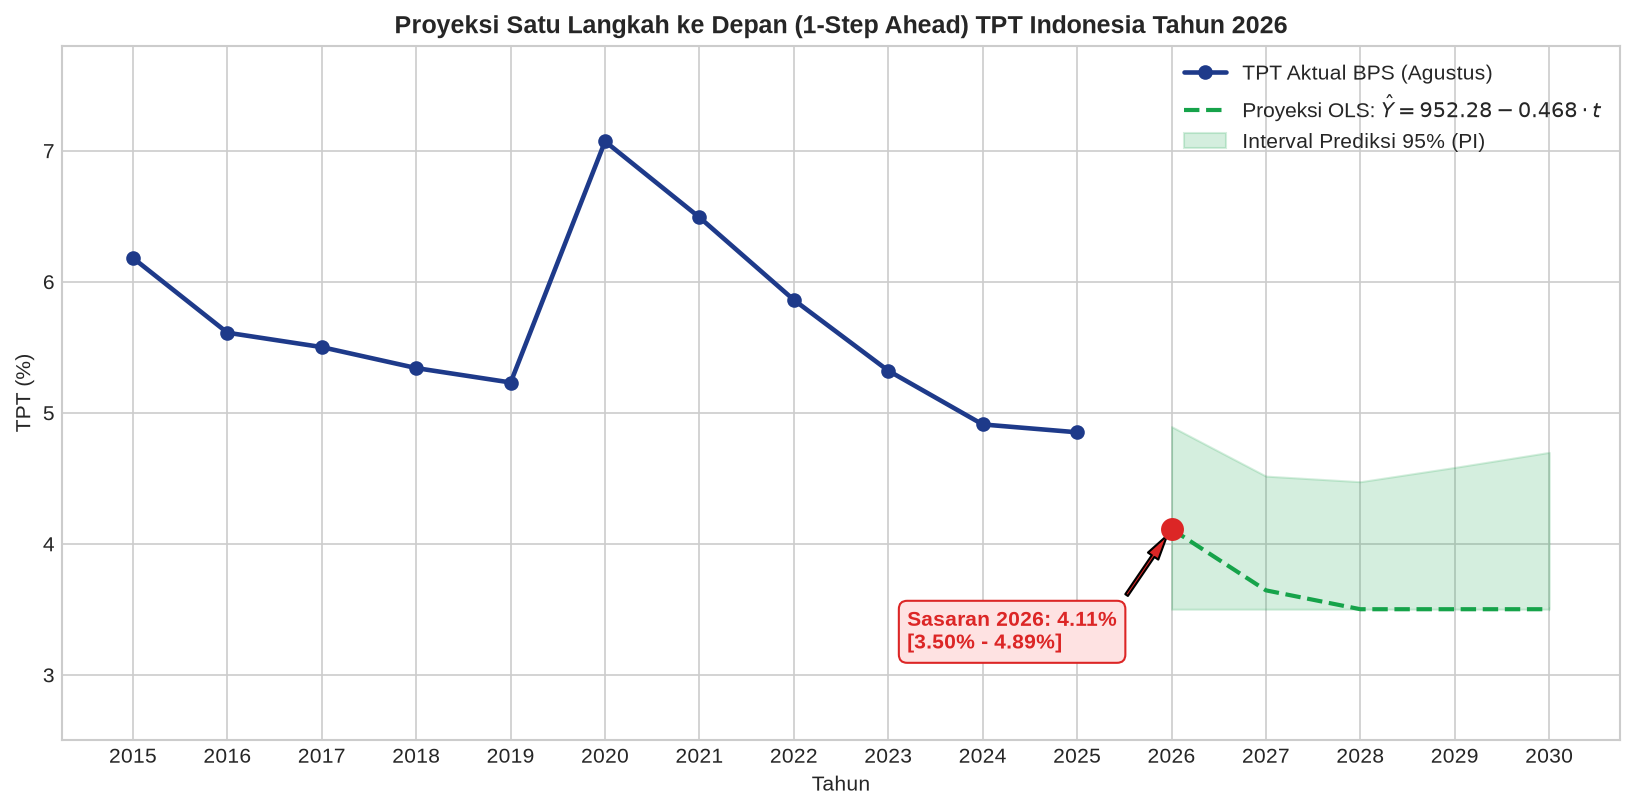

In [3]:
plt.figure(figsize=(11, 5.5))

# Data Historis
plt.plot(df_ts['Tahun'], df_ts['TPT_Agustus'], 'o-', color='#1e3a8a', linewidth=2.2, label='TPT Aktual BPS (Agustus)')

# Garis Horizon
horizon_df = pd.DataFrame(res_2026.multi_year_horizon)
plt.plot(horizon_df['year'], horizon_df['forecast_agustus'], '--', color='#16a34a', linewidth=2, label=r'Proyeksi OLS: $\hat{Y} = 952.28 - 0.468 \cdot t$')
plt.fill_between(horizon_df['year'], horizon_df['pi_lower'], horizon_df['pi_upper'], color='#16a34a', alpha=0.18, label='Interval Prediksi 95% (PI)')

# Titik Sasaran 2026
plt.scatter([2026], [res_2026.point_forecast], color='#dc2626', s=100, zorder=5)
plt.annotate(f"Sasaran 2026: {res_2026.point_forecast:.2f}%\n[{res_2026.pi_lower_95:.2f}% - {res_2026.pi_upper_95:.2f}%]",
             xy=(2026, res_2026.point_forecast), xytext=(2023.2, 3.2),
             arrowprops=dict(facecolor='#dc2626', shrink=0.08, width=1.5, headwidth=6),
             fontweight='bold', color='#dc2626', bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee2e2', edgecolor='#dc2626'))

plt.title("Proyeksi Satu Langkah ke Depan (1-Step Ahead) TPT Indonesia Tahun 2026", fontweight='bold')
plt.xlabel("Tahun")
plt.ylabel("TPT (%)")
plt.xticks(range(2015, 2031))
plt.ylim(2.5, 7.8)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Serialisasi Model & Penyimpanan Artifak

In [4]:
metadata = {
    "model_name": "LinearTrendModel",
    "base_year": 2020,
    "target_year": 2026,
    "r2": float(model.r2_),
    "se": float(model.se_),
    "slope": float(model.slope_),
    "intercept": float(model.intercept_),
    "forecast_2026_agustus": float(res_2026.point_forecast),
    "forecast_2026_februari": float(res_2026.point_forecast_february),
    "pi_lower_95": float(res_2026.pi_lower_95),
    "pi_upper_95": float(res_2026.pi_upper_95)
}

saved_model_path, saved_meta_path = ModelPersistence.save(
    model=model,
    metadata=metadata,
    model_path='experiments/artifacts/laborcast_model.joblib',
    metadata_path='experiments/artifacts/laborcast_metadata.json'
)

print(f"Model berhasil disimpan ke: {saved_model_path}")
print(f"Metadata berhasil disimpan ke: {saved_meta_path}")

Model berhasil disimpan ke: experiments/artifacts/laborcast_model.joblib
Metadata berhasil disimpan ke: experiments/artifacts/laborcast_metadata.json


## Kesimpulan Akhir
Proyek peramalan *LaborCast* telah selesai secara menyeluruh. Proyeksi Tingkat Pengangguran Terbuka tahun 2026 berada pada nilai **$4{,}11\%$** (Agustus) dan **$4{,}02\%$** (Februari) dengan rentang toleransi $95\%$ sebesar $[3{,}50\% \ \text{s.d.} \ 4{,}89\%]$.